# NFCS 2018 frente a Japón

En este notebook comparamos a los inversionistas de Estados Unidos (NFCS 2018) con los de Japón (Bawalle, Khan y Kadoya, 2025). aqui queremos ver dos cosas: si los dos grupos se parecen y si quienes venden en una caída tienen el mismo perfil en los dos países.

Cómo armamos la tabla de la NFCS, paso a paso y con el porqué de cada decisión, está en `docs/nfcs.md`. El código está en `bolsalab/nfcs.py`; aquí solo mostramos resultados.

> **Sobre los datos de la NFCS.** Son propiedad exclusiva de la FINRA Investor Education Foundation. Usamos la encuesta de inversionistas 2018 (recogida en julio de 2018) unida con la encuesta State-by-State 2018, y convertimos varias respuestas a la forma de la encuesta japonesa como se explica en `docs/nfcs.md`. Este notebook solo muestra totales y porcentajes, nunca respuestas de personas.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from bolsalab.features import TRAINING_FILE
from bolsalab.nfcs import NFCS_FEATURES, build_table, load_nfcs_2018, select_respondents

survey = load_nfcs_2018()
respondents = select_respondents(survey)
japan = pd.read_parquet(TRAINING_FILE)
usa = build_table(respondents, japan)

## 1. Quiénes quedaron

Empezamos con las 2.003 personas de la encuesta de inversionistas. Dejamos a quienes dijeron qué hicieron en la caída de febrero de 2018 y, de ellas, a quienes respondieron las preguntas que en Japón no tienen la opción "no sabe".

In [2]:
answered_crash = survey["D20"].isin([1, 2, 3])
pd.DataFrame({
    "Personas": [len(survey), answered_crash.sum(), len(usa)],
    "Vendieron": [survey["D20"].eq(2).sum(), survey.loc[answered_crash, "D20"].eq(2).sum(), usa["sold"].sum()],
}, index=["Encuesta completa", "Dijeron qué hicieron en la caída",
          "Tabla final (respondieron conocimiento, riesgo e inversiones)"])

,Personas,Vendieron
Encuesta completa,2003,87
Dijeron qué hicieron en la caída,1942,87
"Tabla final (respondieron conocimiento, riesgo e inversiones)",1825,84


## 2. ¿Se parecen los inversionistas de los dos países?

Para cada variable mostramos el promedio. En las de sí o no, el promedio es el porcentaje que respondió sí.

In [3]:
labels = {
    "sold": "Vendió en la caída",
    "knows_interest": "Acierta interés compuesto",
    "knows_inflation": "Acierta inflación",
    "knows_diversification": "Acierta diversificación",
    "overconfidence": "Exceso de confianza",
    "male": "Hombre",
    "university": "Título universitario",
    "married": "Casado",
    "has_children": "Tiene hijos",
    "employed": "Tiene empleo",
}
shares = pd.DataFrame({
    "Japón": japan[list(labels)].mean() * 100,
    "EE. UU.": usa[list(labels)].mean() * 100,
}).rename(index=labels).round(1)
shares.columns = ["Japón (%)", "EE. UU. (%)"]
shares

,Japón (%),EE. UU. (%)
Vendió en la caída,19.9,4.6
Acierta interés compuesto,82.1,86.9
Acierta inflación,80.6,79.3
Acierta diversificación,78.1,72.4
Exceso de confianza,7.5,47.8
Hombre,67.0,57.8
Título universitario,65.0,57.0
Casado,69.5,63.3
Tiene hijos,47.5,70.7
Tiene empleo,91.9,52.2


In [4]:
averages = pd.DataFrame({
    "Japón": japan[["age", "knowledge_confidence", "risk_aversion"]].mean(),
    "EE. UU.": usa[["age", "knowledge_confidence", "risk_aversion"]].mean(),
}).rename(index={
    "age": "Edad (años)",
    "knowledge_confidence": "Confianza en lo que sabe (1 a 5)",
    "risk_aversion": "Aversión al riesgo (0 a 1)",
}).round(2)
averages

,Japón,EE. UU.
Edad (años),47.01,56.09
Confianza en lo que sabe (1 a 5),2.71,4.12
Aversión al riesgo (0 a 1),0.55,0.44


Lo que más cambia entre los dos países:

- **Cuánto vendieron.** En Japón vendió el 19,9 % y en EE. UU. el 4,6 %. No es raro: la caída de febrero de 2018 fue de cerca de 10 % y la de marzo de 2020 fue mucho más fuerte.
- **La confianza.** Los estadounidenses se creen mucho más expertos: casi la mitad tiene exceso de confianza, contra el 7,5 % en Japón. Y eso aunque aciertan las tres preguntas en proporciones parecidas.
- **Edad y empleo.** Los de EE. UU. son mayores (56 años contra 47) y solo la mitad trabaja; en Japón trabaja el 92 %. Muchos de los estadounidenses sin empleo son jubilados.

## 3. ¿Quién vende más en cada país?

Como en Japón se vendió mucho más, no sirve comparar los porcentajes directamente. Comparamos **cuántas veces más vende un grupo que el otro** dentro de su propio país. Por ejemplo, si quienes fallan una pregunta venden el 20 % y quienes aciertan el 10 %, los que fallan venden 2 veces más. Un valor mayor que 1 quiere decir que ese grupo vende más; menor que 1, que vende menos.

In [5]:
groups = {
    "Exceso de confianza (sí vs. no)": ("overconfidence", 1),
    "Falla interés compuesto": ("knows_interest", 0),
    "Falla inflación": ("knows_inflation", 0),
    "Falla diversificación": ("knows_diversification", 0),
    "Hombre (vs. mujer)": ("male", 1),
    "Tiene empleo (vs. no)": ("employed", 1),
    "Título universitario (vs. no)": ("university", 1),
    "Casado (vs. no)": ("married", 1),
    "Tiene hijos (vs. no)": ("has_children", 1),
}


def times_more(table, column, group):
    rate = table.groupby(column)["sold"].mean()
    return rate[group] / rate[1 - group]


ratios = pd.DataFrame({
    "Japón": {name: times_more(japan, col, g) for name, (col, g) in groups.items()},
    "EE. UU.": {name: times_more(usa, col, g) for name, (col, g) in groups.items()},
}).round(2)
ratios["¿Misma dirección?"] = ((ratios["Japón"] > 1) == (ratios["EE. UU."] > 1)).map({True: "Sí", False: "No"})
ratios

,Japón,EE. UU.,¿Misma dirección?
Exceso de confianza (sí vs. no),1.47,2.73,Sí
Falla interés compuesto,1.35,2.97,Sí
Falla inflación,1.35,7.66,Sí
Falla diversificación,1.59,3.18,Sí
Hombre (vs. mujer),1.95,1.25,Sí
Tiene empleo (vs. no),0.71,3.14,No
Título universitario (vs. no),0.89,0.83,Sí
Casado (vs. no),0.96,0.81,Sí
Tiene hijos (vs. no),0.99,0.67,Sí


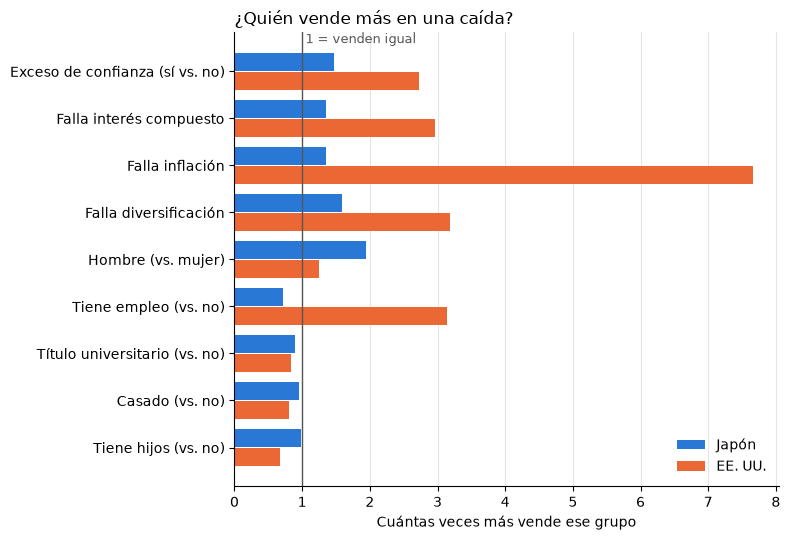

In [6]:
JAPAN_COLOR, USA_COLOR = "#2a78d6", "#eb6834"
order = ratios.index[::-1]
positions = range(len(order))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([p + 0.2 for p in positions], ratios.loc[order, "Japón"], height=0.38,
        color=JAPAN_COLOR, label="Japón")
ax.barh([p - 0.2 for p in positions], ratios.loc[order, "EE. UU."], height=0.38,
        color=USA_COLOR, label="EE. UU.")
ax.axvline(1, color="#555555", linewidth=1)
ax.text(1.05, len(order) - 0.4, "1 = venden igual", color="#555555", fontsize=9)
ax.set_yticks(list(positions), order)
ax.set_xlabel("Cuántas veces más vende ese grupo")
ax.set_title("¿Quién vende más en una caída?", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Lo que encontramos

- **El conocimiento financiero y el exceso de confianza apuntan igual en los dos países.** Quien falla cualquiera de las tres preguntas vende más, y quien tiene exceso de confianza también. En EE. UU. la diferencia es incluso mayor que en Japón. Es la primera señal de que lo que aprende el modelo japonés sobre estas variables podría servir fuera de Japón.
- **Algunas variables cambian de dirección.** En Japón vende menos quien tiene empleo; en EE. UU., más. Probablemente porque en EE. UU. muchos sin empleo son jubilados, que casi no vendieron. Ser hombre pesa mucho en Japón y poco en EE. UU.
- **Título y estado civil casi no separan a quien vende** en ninguno de los dos países. Tener hijos no cambia nada en Japón; en EE. UU., quien tiene hijos vende un poco menos.

Estas comparaciones miran una variable a la vez. El siguiente paso es probar el modelo japonés completo en la tabla de EE. UU.

## Límites

- En EE. UU. solo vendieron 84 personas, así que sus cifras cambian mucho con pocas personas. La de inflación (7,7 veces) hay que leerla con cuidado.
- La NFCS no trae `urban` ni `short_term_view`, y la edad, la confianza, el riesgo, el ingreso y las inversiones se convirtieron con decisiones nuestras como equipo. Todas están explicadas en `docs/nfcs.md`.
- No sabemos qué pregunta usó Japón para el riesgo, así que no entró en la comparación.